In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df =pd.read_csv('dataset/isods_forex/isods_train_small_1000.csv')
df

,Open,High,Low,Close,Volume,body,upper_tail,lower_tail,up_down
0,1.45865,1.45885,1.45856,1.45873,5004.3375,0.8,1.2,0.9,0
1,1.45883,1.45883,1.45847,1.45863,4649.9000,-2.0,0.0,1.6,1
2,1.45863,1.45896,1.45845,1.45886,5283.9500,2.3,1.0,1.8,1
3,1.45865,1.45905,1.45842,1.45895,5370.3375,3.0,1.0,2.3,0
4,1.45902,1.45905,1.45857,1.45887,3738.9375,-1.5,0.3,3.0,1
...,...,...,...,...,...,...,...,...,...
995,1.47687,1.47701,1.47598,1.47622,2200.4000,-6.5,1.4,2.4,1
996,1.47626,1.47678,1.47595,1.47632,1416.6000,0.6,4.6,3.1,1
997,1.47627,1.47709,1.47603,1.47692,1418.7000,6.5,1.7,2.4,1
998,1.47700,1.47756,1.47657,1.47732,1718.9000,3.2,2.4,4.3,0


In [3]:
# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=20, is_test = False):
    dataX, dataY_Regression, dataY_Classification = [], [], []
    
    if(is_test):
        X = dataset
    else:
        X = dataset[:,0:-1]
        Y_C = dataset[:,-1]
      
    if not (is_test):
        close = np.expand_dims(dataset[:,3], axis=1)
        close_scaler = MinMaxScaler(copy=True,feature_range=(0, 1))
        close_scaler.fit(close)    
        scaler = MinMaxScaler(copy=True,feature_range=(0, 1))
        X = scaler.fit_transform(X)
    
    for i in range(len(dataset)-look_back):
        if(is_test):
            a = X[i:(i+look_back),:]
            dataX.append(a)
            dataY_Regression.append(X[i + look_back, 3])
            
            if(i + look_back < len(X) - 1):
                if(X[i + look_back + 1, 3] > X[i + look_back, 3]): #TODO:
                    dataY_Classification.append([1,0])
                else:
                    dataY_Classification.append([0,1])
            else:
                dataY_Classification.append([1,0])       
        else:
            a = X[i:(i+look_back),:]
            dataX.append(a)
            dataY_Regression.append(X[i + look_back, 3])
            
            if(Y_C[i + look_back - 1] == 1):
                dataY_Classification.append([1,0])
            else:
                dataY_Classification.append([0,1])
    
    if (is_test):
        return np.array(dataX), np.array(dataY_Regression), np.array(dataY_Classification)
    else:
        return np.array(dataX), np.array(dataY_Regression), np.array(dataY_Classification), scaler, close_scaler

In [4]:
def plot_confusion_matrix(cm,
                          target_names,
                          title='Confusion matrix',
                          cmap=None,
                          normalize=True):

    import matplotlib.pyplot as plt
    import numpy as np
    import itertools

    accuracy = np.trace(cm) / float(np.sum(cm))
    misclass = 1 - accuracy

    if cmap is None:
        cmap = plt.get_cmap('Blues')

    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()

    if target_names is not None:
        tick_marks = np.arange(len(target_names))
        plt.xticks(tick_marks, target_names, rotation=45)
        plt.yticks(tick_marks, target_names)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]


    thresh = cm.max() / 1.5 if normalize else cm.max() / 2
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        if normalize:
            plt.text(j, i, "{:0.4f}".format(cm[i, j]),
                     horizontalalignment="center",
                     color="white" if cm[i, j] > thresh else "black")
        else:
            plt.text(j, i, "{:,}".format(cm[i, j]),
                     horizontalalignment="center",
                     color="white" if cm[i, j] > thresh else "black")


    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label\naccuracy={:0.4f}; misclass={:0.4f}'.format(accuracy, misclass))
    plt.show()

In [5]:
data_values = df.values
data_values = data_values.astype('float32')

In [6]:
X, Y_R, Y_C, scaler, close_scaler  = create_dataset(data_values, look_back=5)

In [7]:
X_train, X_val, y_train, y_val = train_test_split(X, Y_C,test_size = 0.2)

In [8]:
X_train.shape, y_train.shape

((796, 5, 8), (796, 2))

In [9]:
from tqdm.notebook import tqdm
import cattorch
from cattorch import nn
from cattorch.optim import Adam


class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm_1 = nn.LSTM(8, 128)
        self.classifier = nn.Linear(128, 2)
        self.dropout = nn.Dropout(p=0.2)
        self.loss_fn = nn.CrossEntropyLoss()

        nn.init.xavier_normal_(self.lstm_1.weight_ih)
        nn.init.xavier_normal_(self.lstm_1.weight_hh)

        if self.lstm_1.bias_ih is not None:
            self.lstm_1.bias_ih.data.zero_()
        if self.lstm_1.bias_hh is not None:
            self.lstm_1.bias_hh.data.zero_()

        nn.init.xavier_normal_(self.classifier.weight)
        if self.classifier.bias is not None:
            self.classifier.bias.data.zero_()

    def forward(self, x: cattorch.Tensor, y: cattorch.Tensor = None):
        x = x.permute(1, 0, 2)
        hidden_states, (out, _) = self.lstm_1(x)
        out = (cattorch.silu(out) + cattorch.silu(hidden_states.mean(dim=0))) / 2
        out = self.dropout(out)
        pred = self.classifier(out)
        if y is not None:
            loss = self.loss_fn(pred, y)
            return pred, loss
        return pred


model = SimpleLSTM()
params = list(model.parameters())
optim = Adam(params, lr=1e-5)
train_X = cattorch.Tensor(X_train)
train_Y = cattorch.Tensor(y_train[:, 0])

val_X = cattorch.Tensor(X_val)
val_Y = cattorch.Tensor(y_val[:, 0])

/home/chang/.projs/cat-torch-from-scratch/cattorch/backend/_array.py:25: UserWarning: Cupy not installed!!!
  warnings.warn("Cupy not installed!!!")


In [10]:
import numpy as np

epochs = 7
batch_size = 8

for e in range(epochs):
    indices = np.random.permutation(train_X.shape[0])
    X_train = train_X[indices]
    y_train = train_Y[indices]
    epoch_loss, val_loss = 0.0, 0.0
    num_batches, val_batches = 0, 0
    pbar = tqdm(range(0, X_train.shape[0], batch_size))
    model = model.train()
    for it in pbar:
        X_batch = X_train[it:it+batch_size]
        y_batch = y_train[it:it+batch_size]
        
        logits, loss = model(X_batch, y_batch)  # (B, num_classes)
        # backward + step
        loss.backward()
        optim.step()
        optim.zero_grad()

        epoch_loss += loss.data.asnumpy()
        num_batches += 1
        pbar.set_description("Epoch " + str(e+1) + " - Loss: %.5f" % (epoch_loss/num_batches))
    
    model = model.eval()
    for it in range(0, val_X.shape[0], batch_size):
        X_batch = val_X[it:it+batch_size]
        y_batch = val_Y[it:it+batch_size]
        
        y_val_hat, batch_val_loss = model(X_batch, y_batch)
        val_loss += batch_val_loss.data.asnumpy()
        val_batches += 1
    print(f"train loss: {epoch_loss/num_batches}, val loss: {val_loss/val_batches}")

print("Training finished.")


  0%|          | 0/100 [00:00<?, ?it/s]

train loss: 0.6935456991195679, val loss: 0.6950089335441589


  0%|          | 0/100 [00:00<?, ?it/s]

train loss: 0.6930049657821655, val loss: 0.6949789524078369


  0%|          | 0/100 [00:00<?, ?it/s]

train loss: 0.6933338642120361, val loss: 0.6948874592781067


... (4 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

train loss: 0.6934900879859924, val loss: 0.6947189569473267


  0%|          | 0/100 [00:00<?, ?it/s]

train loss: 0.6931036114692688, val loss: 0.6946414709091187
Training finished.


In [11]:
model = model.eval()
logits = model(val_X)
pred = logits.argmax(dim = -1)
# print("Accuracy:", len(pred[y_val[:,0] == pred.asnumpy()]) / pred.shape[0])
# from sklearn.metrics import confusion_matrix
array = confusion_matrix(y_val[:,0], pred.asnumpy())

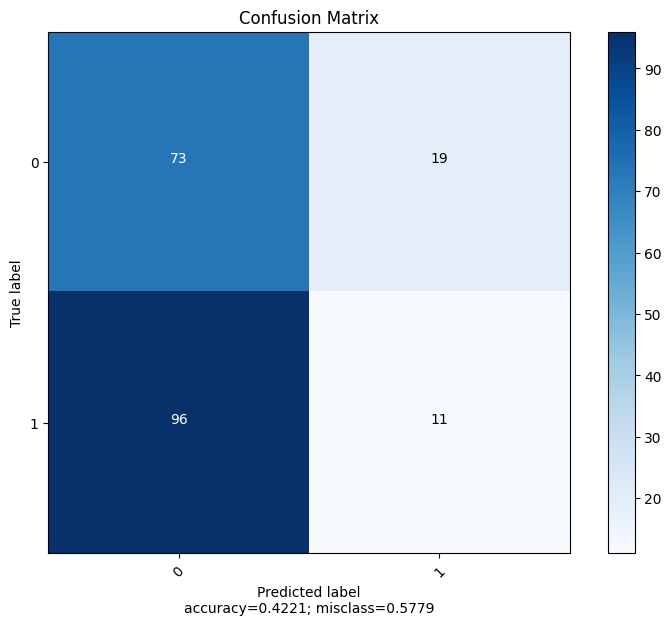

In [12]:
plot_confusion_matrix(cm           = array,
                      normalize    = False,
                      target_names = ['0', '1'],
                      title        = "Confusion Matrix")